In [ ]:

import pandas as pd

comparison_df = pd.DataFrame({
    'Model': ['One-Class SVM', 'Isolation Forest'],
    'Accuracy': [52.47, 23.47],
    'Precision': [95.60, 73.17],
    'Recall': [42.75, 7.37],
    'F1 Score': [59.08, 13.39],
    'ROC-AUC': [73.19, 54.36]
})

print("Model Comparison Results")
display(comparison_df)

comparison_df.to_csv('Model_Comparison_Results.csv', index=False)

print("Comparison results saved successfully!")


Model Comparison Results


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,One-Class SVM,52.47,95.60,42.75,59.08,73.19
1,Isolation Forest,23.47,73.17,7.37,13.39,54.36


Comparison results saved successfully!


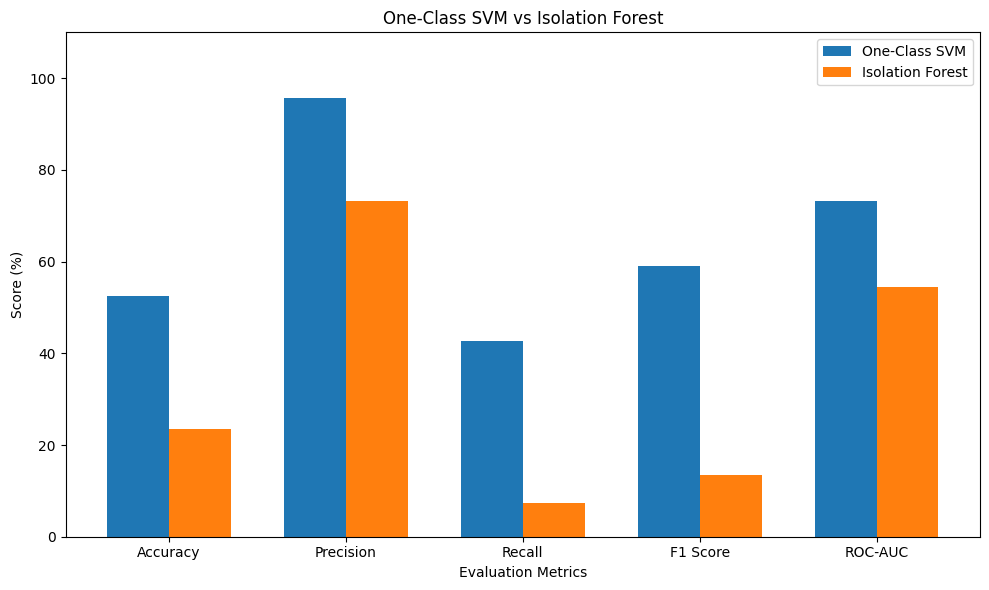

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

svm_values = [52.47, 95.60, 42.75, 59.08, 73.19]
if_values = [23.47, 73.17, 7.37, 13.39, 54.36]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, svm_values, width, label='One-Class SVM')
plt.bar(x + width/2, if_values, width, label='Isolation Forest')

plt.xlabel('Evaluation Metrics')
plt.ylabel('Score (%)')
plt.title('One-Class SVM vs Isolation Forest')
plt.xticks(x, metrics)
plt.ylim(0, 110)
plt.legend()

plt.tight_layout()
plt.savefig('Model_Comparison_Graph.png', dpi=300)
plt.show()


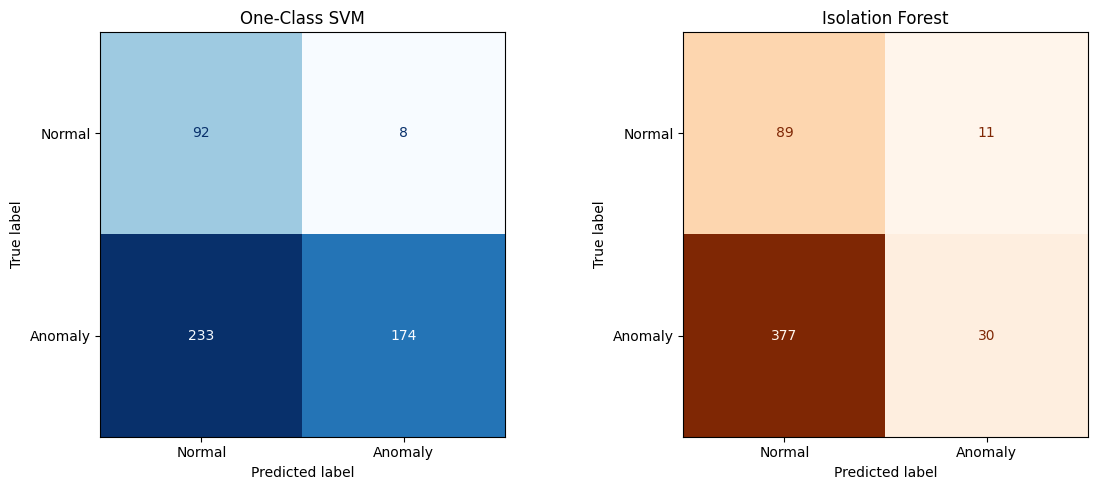

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

svm_cm = np.array([[92, 8],
                   [233, 174]])

if_cm = np.array([[89, 11],
                  [377, 30]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=['Normal', 'Anomaly']
).plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].set_title('One-Class SVM')

ConfusionMatrixDisplay(
    confusion_matrix=if_cm,
    display_labels=['Normal', 'Anomaly']
).plot(ax=axes[1], cmap='Oranges', colorbar=False)

axes[1].set_title('Isolation Forest')

plt.tight_layout()

plt.savefig('Combined_Confusion_Matrix.png',
            dpi=300, bbox_inches='tight')

plt.show()


In [ ]:

import pandas as pd
import numpy as np

y_test = pd.read_csv('y_test.csv')

y_true = y_test.iloc[:, 0].values

test_anomaly_scores = np.load('IF_Test_Anomaly_Scores.npy')

print("Test labels loaded:", len(y_true))
print("Anomaly scores loaded:", len(test_anomaly_scores))


Test labels loaded: 507
Anomaly scores loaded: 507


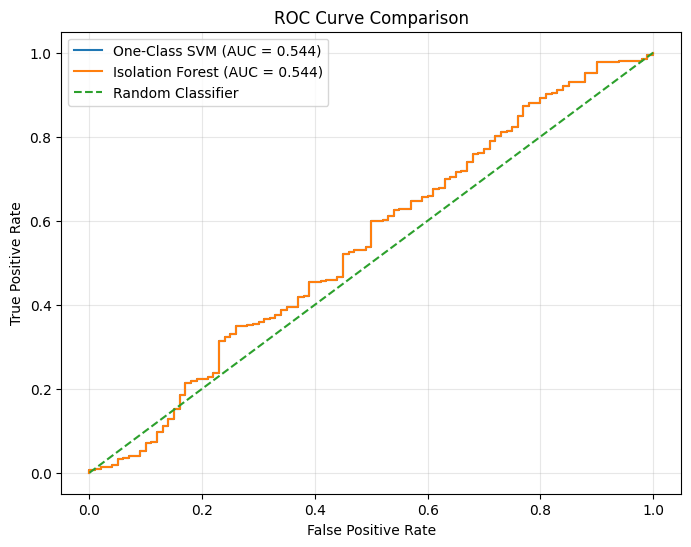

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

if_test_anomaly_scores = np.load('IF_Test_Anomaly_Scores.npy')

svm_fpr, svm_tpr, _ = roc_curve(y_true, test_anomaly_scores)

if_fpr, if_tpr, _ = roc_curve(y_true, if_test_anomaly_scores)

svm_auc = roc_auc_score(y_true, test_anomaly_scores)

if_auc = roc_auc_score(y_true, if_test_anomaly_scores)

plt.figure(figsize=(8, 6))

plt.plot(
    svm_fpr,
    svm_tpr,
    label=f'One-Class SVM (AUC = {svm_auc:.3f})'
)

plt.plot(
    if_fpr,
    if_tpr,
    label=f'Isolation Forest (AUC = {if_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig('Combined_ROC_Curve.png', dpi=300, bbox_inches='tight')

plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_true = pd.read_csv('y_test.csv').iloc[:, 0].to_numpy()

svm_scores = np.load('SVM_Test_Anomaly_Scores.npy')
if_scores = np.load('IF_Test_Anomaly_Scores.npy')

print("Test labels:", len(y_true))
print("SVM scores:", len(svm_scores))
print("Isolation Forest scores:", len(if_scores))

Test labels: 507
SVM scores: 507
Isolation Forest scores: 507


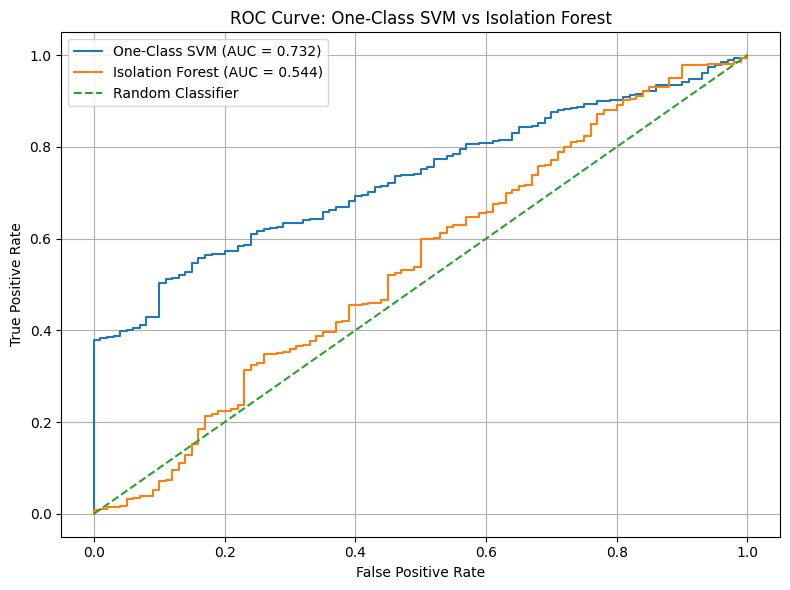

SVM ROC-AUC: 0.731941031941032
Isolation Forest ROC-AUC: 0.5436363636363636


In [ ]:
svm_fpr, svm_tpr, _ = roc_curve(y_true, svm_scores)
if_fpr, if_tpr, _ = roc_curve(y_true, if_scores)

svm_auc = roc_auc_score(y_true, svm_scores)
if_auc = roc_auc_score(y_true, if_scores)

plt.figure(figsize=(8, 6))

plt.plot(svm_fpr, svm_tpr, label=f'One-Class SVM (AUC = {svm_auc:.3f})')
plt.plot(if_fpr, if_tpr, label=f'Isolation Forest (AUC = {if_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: One-Class SVM vs Isolation Forest')
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig('Combined_ROC_Curve.png', dpi=300, bbox_inches='tight')
plt.show()

print("SVM ROC-AUC:", svm_auc)
print("Isolation Forest ROC-AUC:", if_auc)